# **14.  Máquinas de soporte vectorial.**

Temas selectos de aprendizaje de máquina \
Ana Luisa Llamas Martinez

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons, make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [2]:
def graficar_frontera(
    modelo,
    X,
    y,
    titulo="Frontera de decisión",
    mostrar_soporte=True
):
    
    plt.figure(figsize=(8, 6))
    
    x_min = X[:, 0].min() - 0.8
    x_max = X[:, 0].max() + 0.8
    
    y_min = X[:, 1].min() - 0.8
    y_max = X[:, 1].max() + 0.8
    
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 400),
        np.linspace(y_min, y_max, 400)
    )
    
    grid = np.c_[xx.ravel(), yy.ravel()]
    
    Z = modelo.decision_function(grid)
    Z = Z.reshape(xx.shape)
    
    plt.contourf(
        xx,
        yy,
        Z,
        levels=[Z.min(), 0, Z.max()],
        alpha=0.15
    )
    
    plt.contour(
        xx,
        yy,
        Z,
        levels=[-1, 0, 1],
        linestyles=["--", "-", "--"]
    )
    
    for clase in np.unique(y):
        plt.scatter(
            X[y == clase, 0],
            X[y == clase, 1],
            label=f"Clase {clase}",
            s=60
        )
    
    if mostrar_soporte:
        plt.scatter(
            modelo.support_vectors_[:, 0],
            modelo.support_vectors_[:, 1],
            s=160,
            facecolors="none",
            edgecolors="black",
            linewidths=1.4,
            label="Vectores de soporte"
        )
    
    plt.xlabel("$X_1$")
    plt.ylabel("$X_2$")
    plt.title(titulo)
    plt.legend()
    plt.show()

## 14.4 Un problema que no es lineal.

In [3]:
X, y = make_moons(
    n_samples=250,
    noise = 0.20,
    random_state=42
)

y = np.where(y==0, -1, 1)

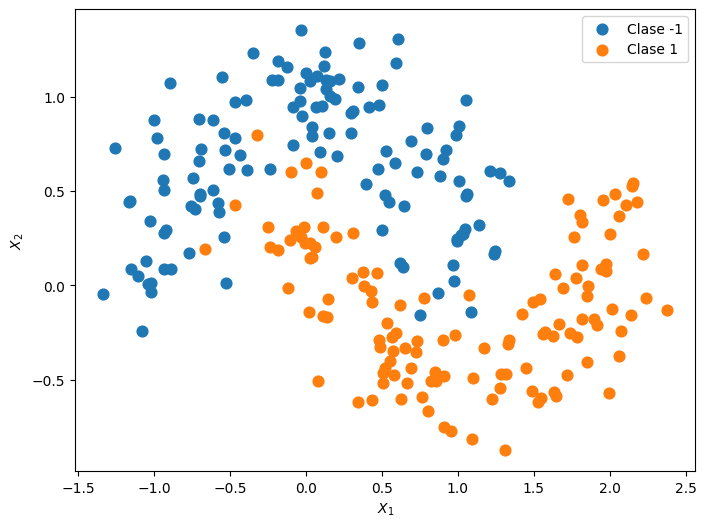

In [4]:
plt.figure(figsize=(8,6))

for clase in np.unique(y):
    plt.scatter(
        X[y==clase, 0],
        X[y==clase, 1],
        label = f"Clase {clase}",
        s = 60
    )

plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.legend()
plt.show()


## 14.5 Intentemos primero una SVM lineal.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

In [6]:
modelo_lineal = Pipeline([
    ("scale",
    StandardScaler()),
    ("svc", 
     SVC(kernel="linear", C = 1))
])

In [7]:
modelo_lineal.fit(X_train, y_train)



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[-1, 1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [8]:
scaler_ajustado = modelo_lineal.named_steps["scale"]

scaler_ajustado.mean_

array([0.49451697, 0.26906967])

In [9]:
scaler_ajustado.scale_

array([0.90581814, 0.51586362])

In [10]:
X_train[:3]

array([[ 1.85108055, -0.05741004],
       [ 0.97397145,  0.02516258],
       [ 1.2816915 , -0.46765409]])

In [11]:
scaler_ajustado.transform(X_train[:3])

array([[ 1.49761141, -0.6328799 ],
       [ 0.52930545, -0.47281312],
       [ 0.86902049, -1.4281367 ]])

In [12]:
prediccion_pipeline = modelo_lineal.predict(X_test)

In [13]:
scaler = StandardScaler()

X_train_escalado = scaler.fit_transform(
    X_train
)

In [14]:
modelo_escalado = SVC(
    kernel="linear",
    C=1
)

modelo_escalado.fit(
    X_train_escalado,
    y_train
)


,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [15]:
X_test_escalado = scaler.transform(
    X_test
)

prediccion_manual = modelo_escalado.predict(X_test_escalado)

In [16]:
prediccion_manual

array([ 1, -1, -1, -1, -1, -1, -1, -1,  1,  1, -1,  1, -1,  1,  1, -1,  1,
        1,  1, -1, -1, -1,  1,  1,  1,  1, -1, -1, -1, -1,  1,  1,  1,  1,
        1,  1, -1, -1,  1,  1, -1,  1, -1,  1, -1, -1, -1, -1,  1, -1, -1,
        1,  1,  1,  1,  1, -1, -1,  1,  1,  1,  1, -1,  1, -1, -1, -1,  1,
        1,  1, -1,  1,  1, -1, -1])

In [17]:
prediccion_pipeline

array([ 1, -1, -1, -1, -1, -1, -1, -1,  1,  1, -1,  1, -1,  1,  1, -1,  1,
        1,  1, -1, -1, -1,  1,  1,  1,  1, -1, -1, -1, -1,  1,  1,  1,  1,
        1,  1, -1, -1,  1,  1, -1,  1, -1,  1, -1, -1, -1, -1,  1, -1, -1,
        1,  1,  1,  1,  1, -1, -1,  1,  1,  1,  1, -1,  1, -1, -1, -1,  1,
        1,  1, -1,  1,  1, -1, -1])

In [18]:
np.array_equal(prediccion_pipeline, prediccion_manual)

True

In [19]:
prediccion_manual == prediccion_pipeline

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True])

In [20]:
df_accuracy = pd.DataFrame({
    "Modelo": [
        "SVM con pipeline"
    ],
    "Accuracy_train": [
        accuracy_score(y_train, modelo_lineal.predict(X_train))
    ],
    "Accuracy_test": [
        accuracy_score(y_test, modelo_lineal.predict(X_test))
    ]
})

df_accuracy

,Modelo,Accuracy_train,Accuracy_test
0,SVM con pipeline,0.845714,0.866667


## 14.6.2 Función para visualizar la frontera.

In [21]:
def graficar_modelo(
    modelo,
    X,
    y,
    titulo="Frontera de decisión"
):
    
    # Crear figura
    plt.figure(figsize=(8, 6))
    
    # Límites de la región que vamos a visualizar
    x_min = X[:, 0].min() - 0.8
    x_max = X[:, 0].max() + 0.8
    
    y_min = X[:, 1].min() - 0.8
    y_max = X[:, 1].max() + 0.8
    
    # Crear una malla de puntos
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 400),
        np.linspace(y_min, y_max, 400)
    )
    
    # Convertir la malla en pares (X1, X2)
    grid = np.c_[
        xx.ravel(),
        yy.ravel()
    ]
    
    # Predecir la clase de cada punto de la malla
    Z_pred = modelo.predict(grid)
    
    # Regresar al formato de la malla
    Z_pred = Z_pred.reshape(xx.shape)
    
    # Colorear las regiones según la clase predicha
    plt.contourf(
        xx,
        yy,
        Z_pred,
        alpha=0.15
    )

    # Evaluar la función de decisión en toda la malla
    Z_decision = modelo.decision_function(grid)
    
    # Esta función está pensada para clasificación binaria
    Z_decision = Z_decision.reshape(xx.shape)
    
    # Sólo incluimos niveles que realmente estén dentro
    # del rango de la función de decisión
    niveles = [
        nivel
        for nivel in [-1, 0, 1]
        if Z_decision.min() <= nivel <= Z_decision.max()
    ]
    
    # Dibujamos los niveles únicamente si existen
    if len(niveles) > 0:
        
        estilos = [
            "-" if nivel == 0 else "--"
            for nivel in niveles
        ]
        
        plt.contour(
            xx,
            yy,
            Z_decision,
            levels=niveles,
            linestyles=estilos
        )
    
    for clase in np.unique(y):
        
        plt.scatter(
            X[y == clase, 0],
            X[y == clase, 1],
            label=f"Clase {clase}",
            s=60
        )
    

    plt.xlabel("$X_1$")
    plt.ylabel("$X_2$")
    plt.title(titulo)
    plt.legend()
    plt.show()


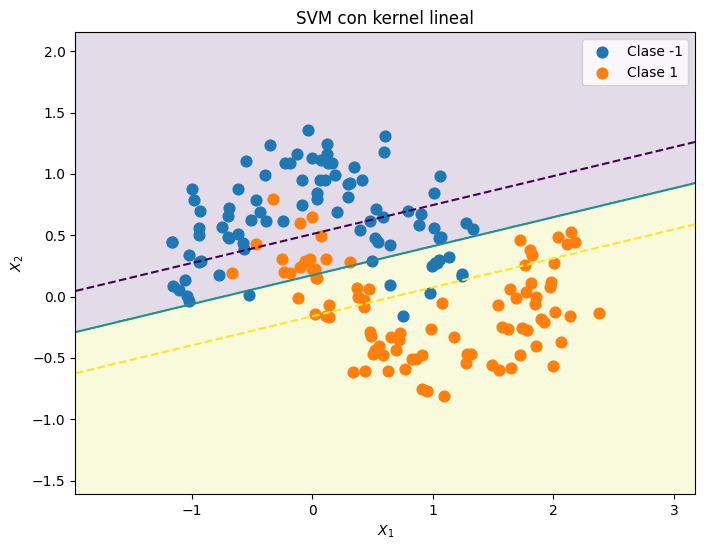

In [22]:
graficar_modelo(
    modelo_lineal,
    X_train,
    y_train,
    titulo="SVM con kernel lineal"
)

## 14.9 Kernel polinomial

In [23]:
modelo_poly2 = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="poly", degree = 2, C = 1, gamma = "scale", coef0 = 1))
])

In [24]:
modelo_poly2.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[-1, 1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


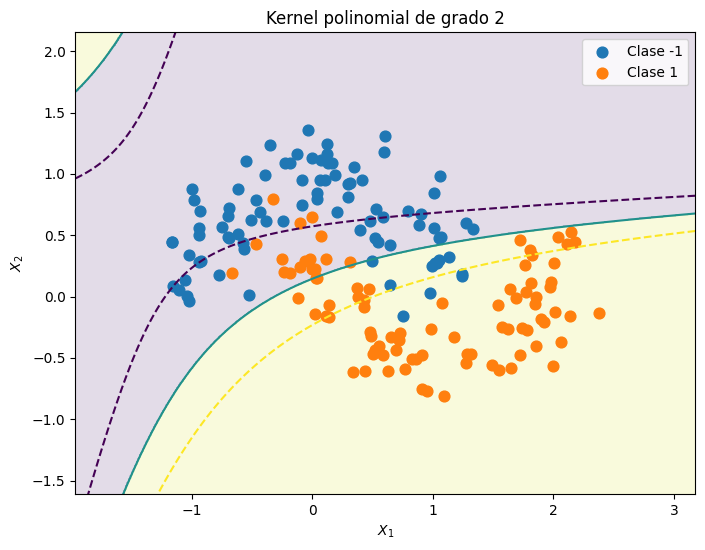

In [25]:
graficar_modelo(modelo_poly2, X_train, y_train, titulo = "Kernel polinomial de grado 2")

In [26]:
df_accuracy = pd.DataFrame({
    "Modelo": [
        "SVM con pipeline"
    ],
    "Accuracy_train": [
        accuracy_score(y_train, modelo_poly2.predict(X_train))
    ],
    "Accuracy_test": [
        accuracy_score(y_test, modelo_poly2.predict(X_test))
    ]
})

df_accuracy

,Modelo,Accuracy_train,Accuracy_test
0,SVM con pipeline,0.845714,0.88


## 14.10 ¿Qué ocurre si aumentamos el grado?

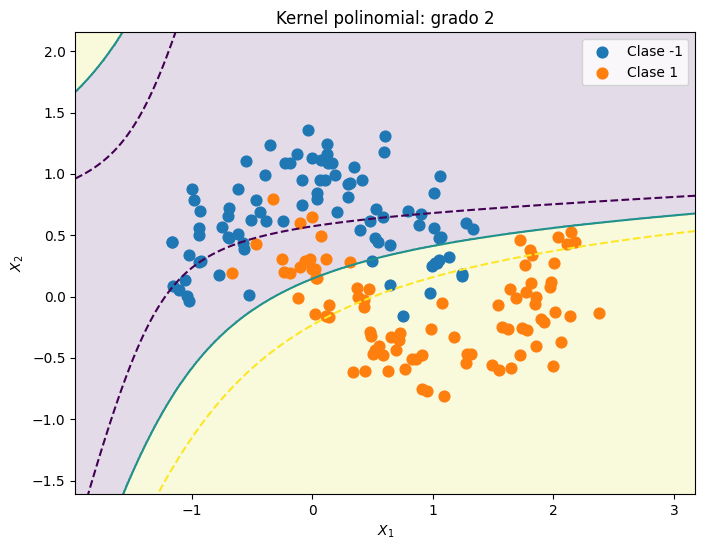

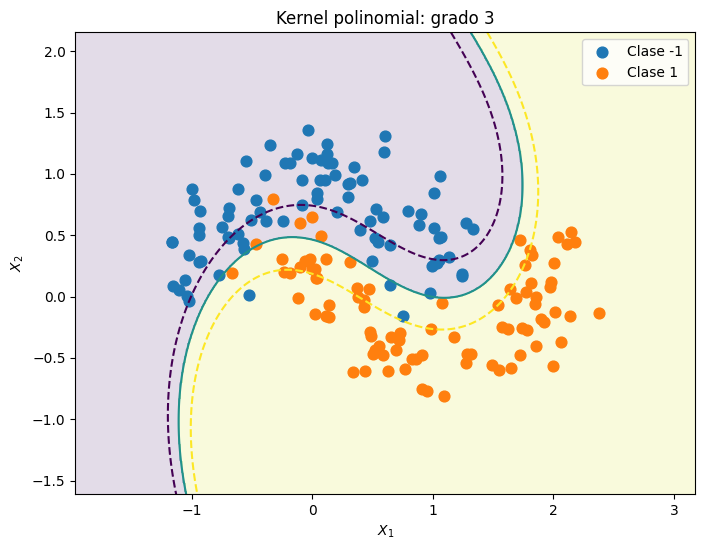

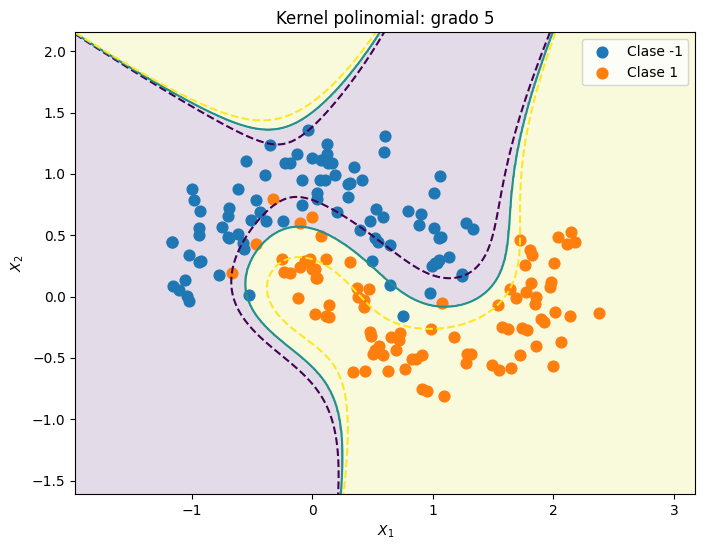

In [27]:
grados = [2, 3, 5]

for grado in grados:
    
    modelo = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svc",
            SVC(
                kernel="poly",
                degree=grado,
                C=1,
                gamma="scale",
                coef0=1
            )
        )
    ])
    
    modelo.fit(
        X_train,
        y_train
    )
    
    graficar_modelo(
        modelo,
        X_train,
        y_train,
        titulo=f"Kernel polinomial: grado {grado}"
    )

## 14.12 Primer SVM con kernel RBF.

In [28]:
modelo_rbf = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svc",
        SVC(
            kernel="rbf",
            C=1,
            gamma=1
        )
    )
])

In [29]:
modelo_rbf.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[-1, 1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


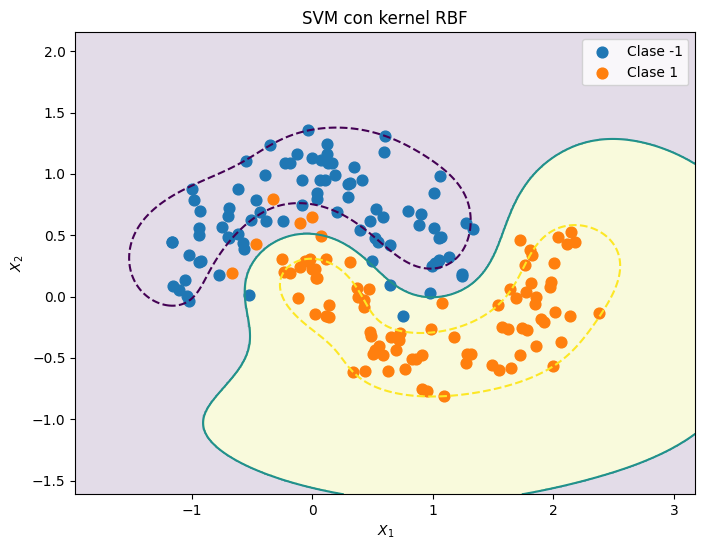

In [30]:
graficar_modelo(
    modelo_rbf,
    X_train,
    y_train,
    titulo="SVM con kernel RBF"
)

In [31]:
print(
    "Accuracy entrenamiento:",
    accuracy_score(
        y_train,
        modelo_rbf.predict(X_train)
    )
)

print(
    "Accuracy prueba:",
    accuracy_score(
        y_test,
        modelo_rbf.predict(X_test)
    )
)

Accuracy entrenamiento: 0.9542857142857143
Accuracy prueba: 0.9466666666666667


## 14.14 Fijamos $C$ y variamos $\gamma$

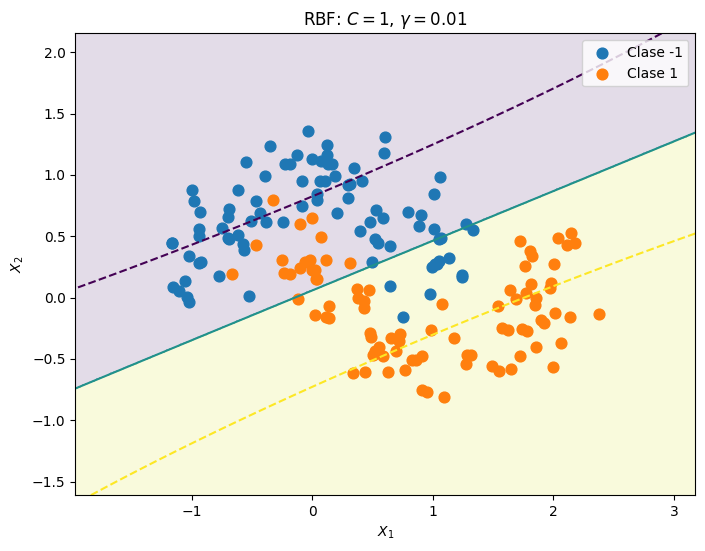

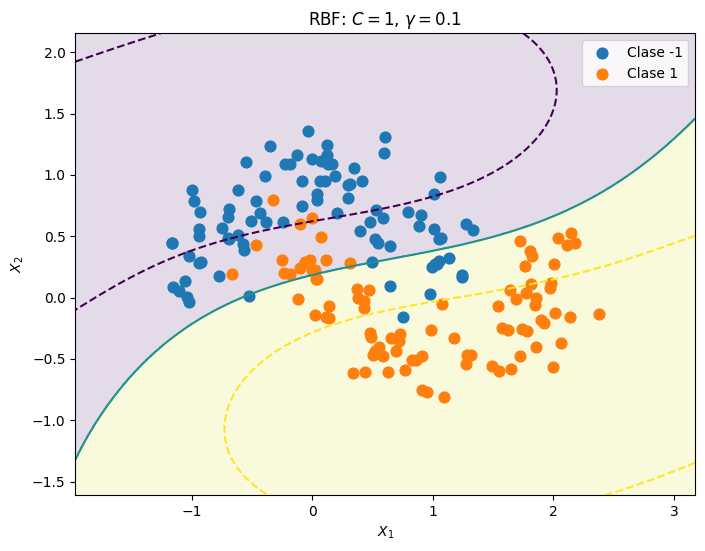

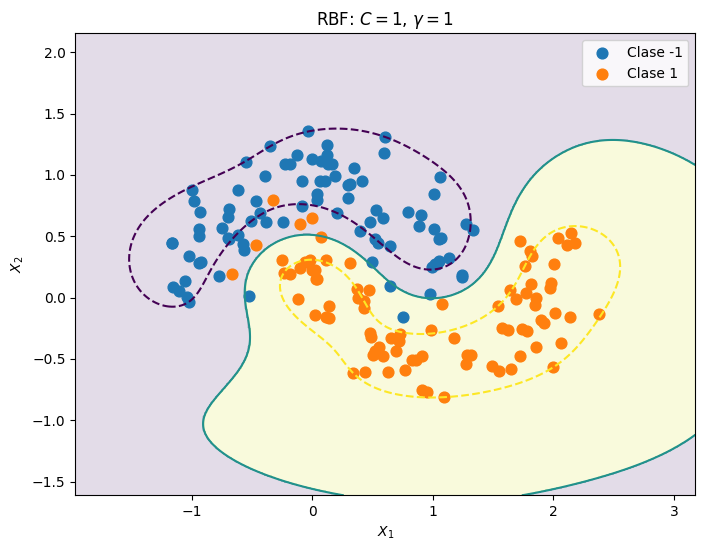

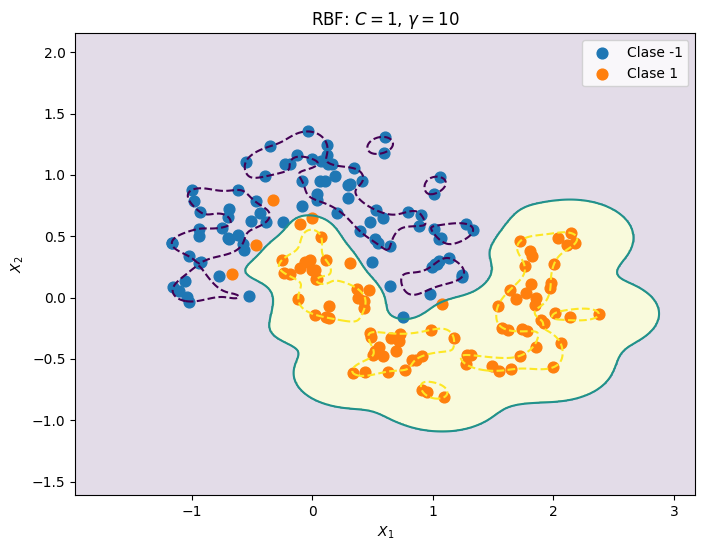

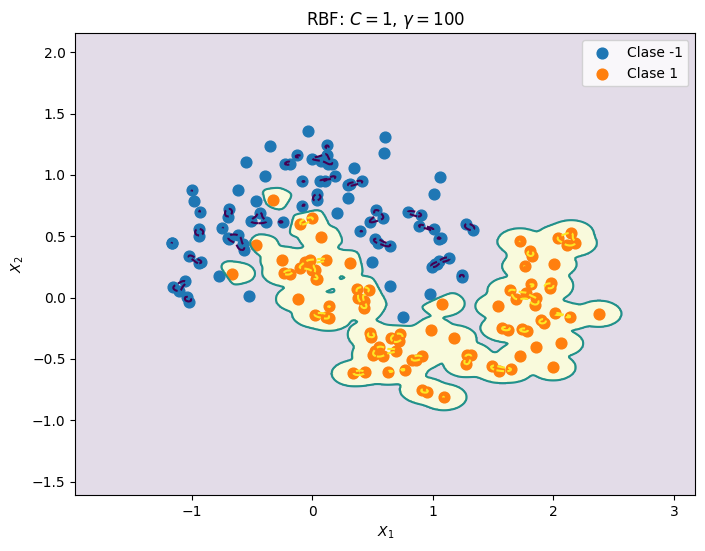

In [32]:
valores_gamma = [
    0.01,
    0.1,
    1,
    10,
    100
]

for gamma in valores_gamma:
    
    modelo = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svc",
            SVC(
                kernel="rbf",
                C=1,
                gamma=gamma
            )
        )
    ])
    
    modelo.fit(
        X_train,
        y_train
    )
    
    graficar_modelo(
        modelo,
        X_train,
        y_train,
        titulo=fr"RBF: $C=1$, $\gamma={gamma}$"
    )

## 14.15 Comparación cuantitativa de $\gamma$

In [33]:
comparacion_gamma = []

for gamma in valores_gamma:
    
    modelo = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svc",
            SVC(
                kernel="rbf",
                C=1,
                gamma=gamma
            )
        )
    ])
    
    modelo.fit(
        X_train,
        y_train
    )
    
    comparacion_gamma.append({
        "gamma": gamma,
        "Accuracy_train": accuracy_score(
            y_train,
            modelo.predict(X_train)
        ),
        "Accuracy_test": accuracy_score(
            y_test,
            modelo.predict(X_test)
        )
    })

comparacion_gamma = pd.DataFrame(
    comparacion_gamma
)

comparacion_gamma

,gamma,Accuracy_train,Accuracy_test
0,0.01,0.822857,0.880000
1,0.10,0.845714,0.880000
2,1.00,0.954286,0.946667
3,10.00,0.982857,0.973333
4,100.00,1.000000,0.893333


## 14.16 Ahora fijamos $\gamma$ y variamos $C$

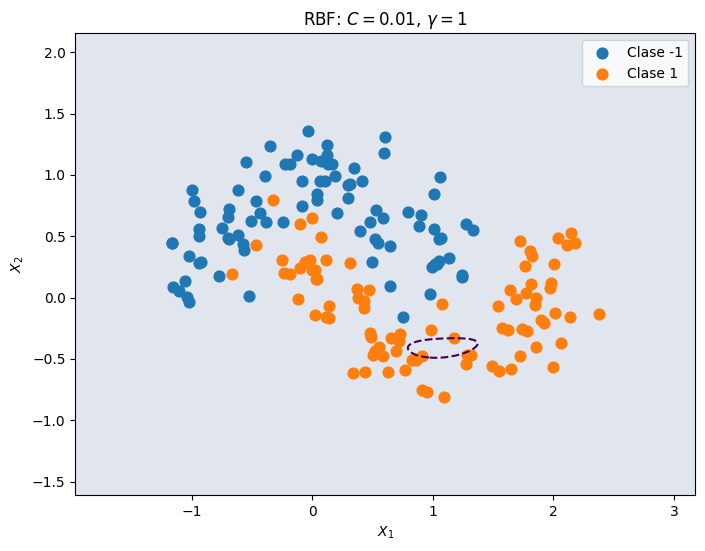

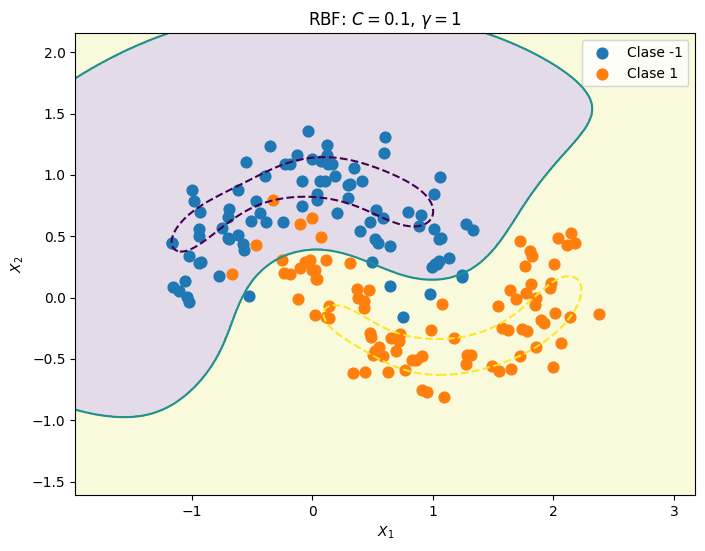

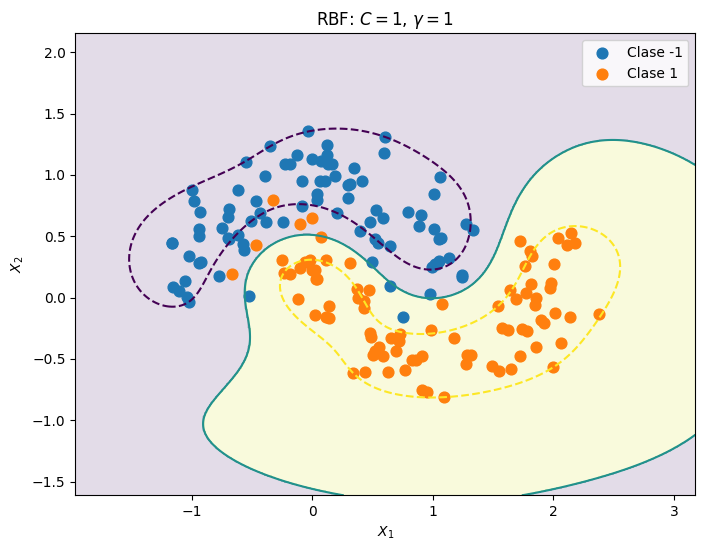

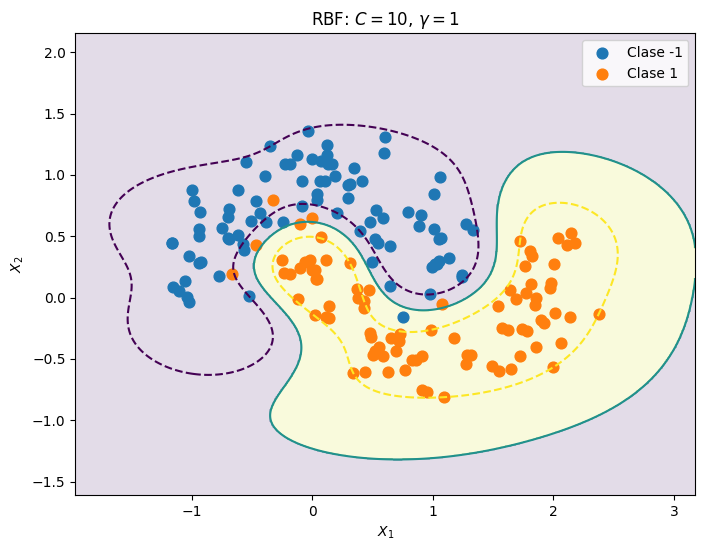

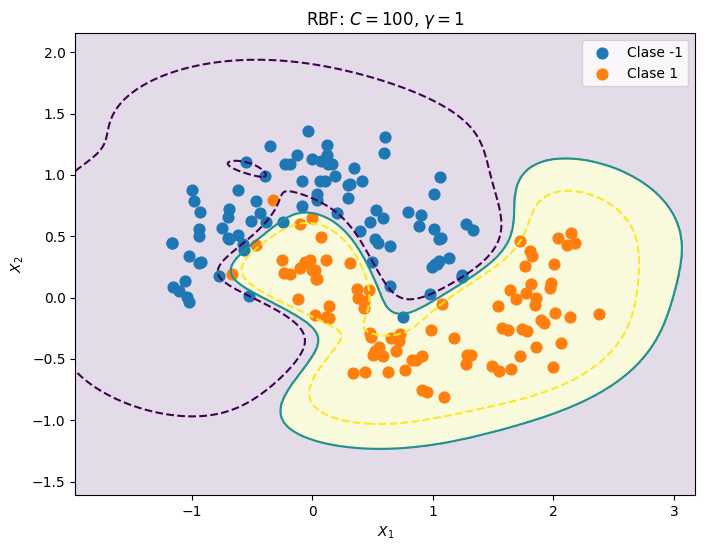

In [34]:
valores_C = [
    0.01,
    0.1,
    1,
    10,
    100
]

for C in valores_C:
    
    modelo = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svc",
            SVC(
                kernel="rbf",
                C=C,
                gamma=1
            )
        )
    ])
    
    modelo.fit(
        X_train,
        y_train
    )
    
    graficar_modelo(
        modelo,
        X_train,
        y_train,
        titulo=fr"RBF: $C={C}$, $\gamma=1$"
    )

## 14.17 $C$ y $\gamma$ interactúan

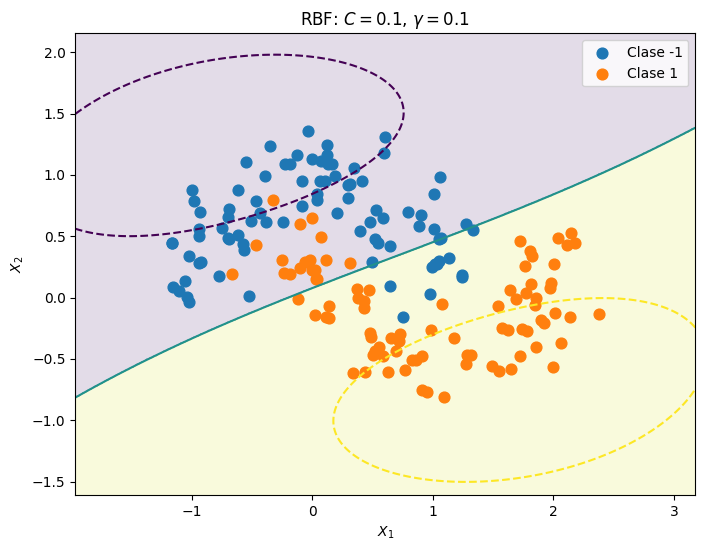

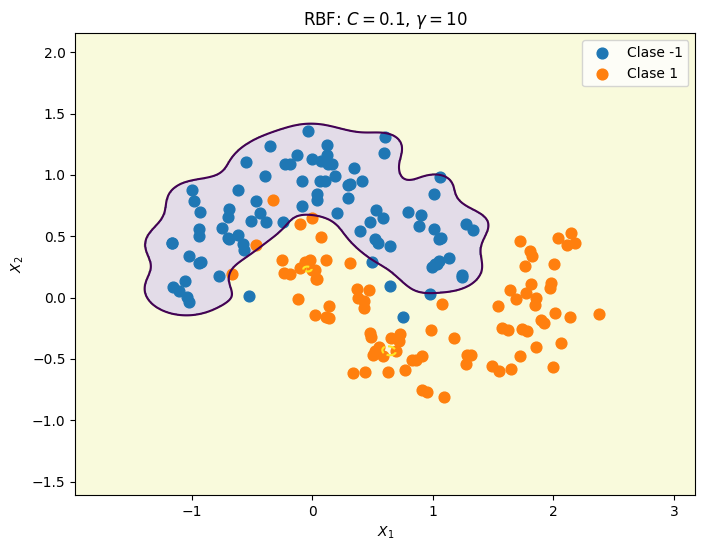

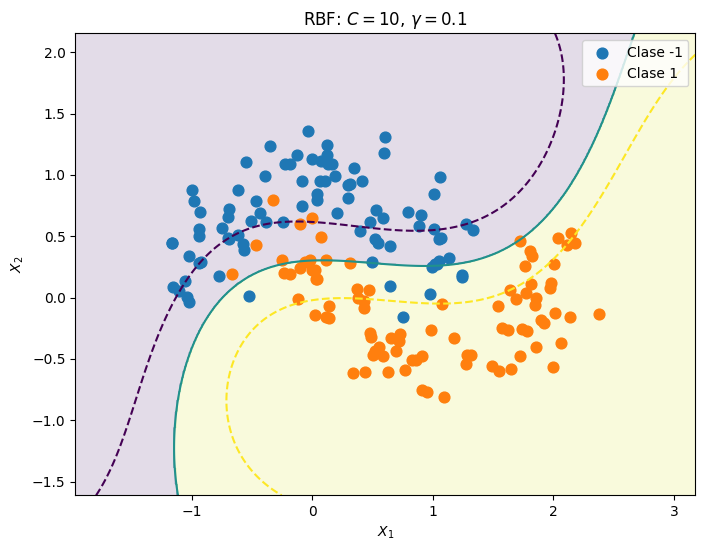

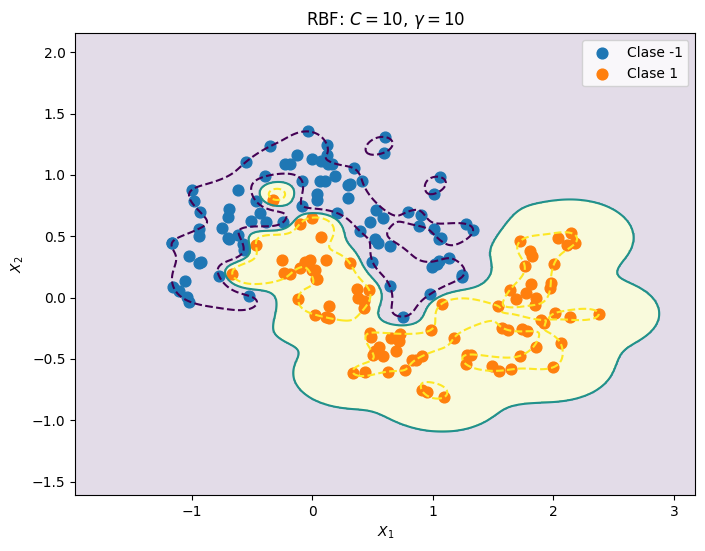

In [35]:
combinaciones = [
    (0.1, 0.1),
    (0.1, 10),
    (10, 0.1),
    (10, 10)
]

for C, gamma in combinaciones:
    
    modelo = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svc",
            SVC(
                kernel="rbf",
                C=C,
                gamma=gamma
            )
        )
    ])
    
    modelo.fit(
        X_train,
        y_train
    )
    
    graficar_modelo(
        modelo,
        X_train,
        y_train,
        titulo=fr"RBF: $C={C}$, $\gamma={gamma}$"
    )

## 14.18 Número de vectores de soporte

In [36]:
svc_rbf = modelo_rbf.named_steps["svc"]

In [37]:
len(svc_rbf.support_)

48

In [38]:
svc_rbf.n_support_

array([24, 24], dtype=int32)

## 14.19 Un segundo ejemplo: círculos concéntricos

In [39]:
X_circulos, y_circulos = make_circles(
    n_samples=300,
    factor=0.4,
    noise=0.10,
    random_state=42
)

In [40]:
y_circulos = np.where(
    y_circulos == 0,
    -1,
    1
)

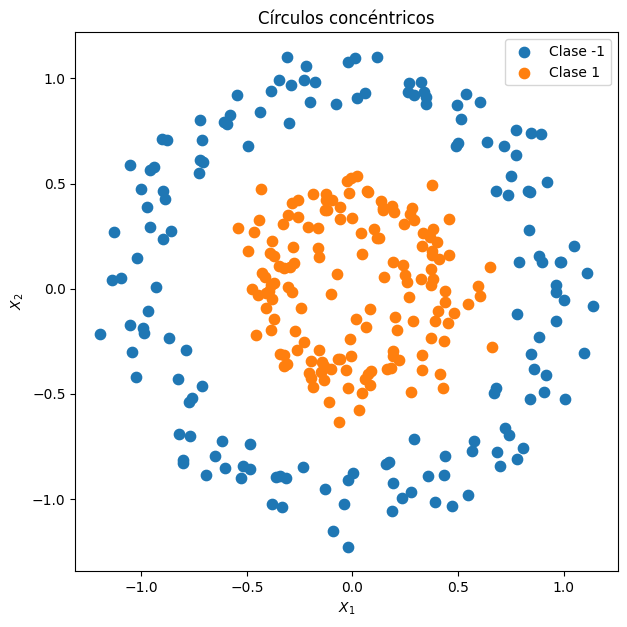

In [41]:
plt.figure(figsize=(7, 7))

for clase in np.unique(y_circulos):
    plt.scatter(
        X_circulos[y_circulos == clase, 0],
        X_circulos[y_circulos == clase, 1],
        label=f"Clase {clase}",
        s=55
    )

plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.title("Círculos concéntricos")
plt.legend()
plt.show()

## 14.20 Kernel lineal vs. RBF

In [42]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_circulos,
    y_circulos,
    test_size=0.30,
    random_state=42,
    stratify=y_circulos
)

In [43]:
modelo_circulos_lineal = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svc",
        SVC(
            kernel="linear",
            C=1
        )
    )
])

modelo_circulos_lineal.fit(
    Xc_train,
    yc_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[-1, 1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [44]:
modelo_circulos_rbf = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svc",
        SVC(
            kernel="rbf",
            C=1,
            gamma=1
        )
    )
])

modelo_circulos_rbf.fit(
    Xc_train,
    yc_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[-1, 1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


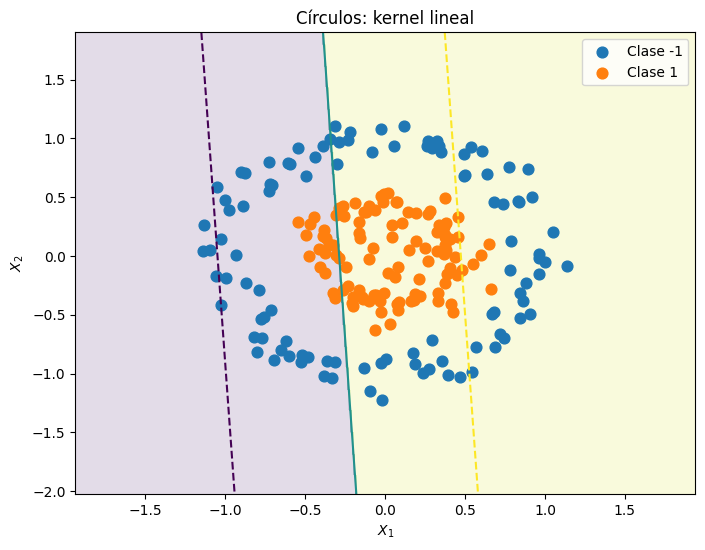

In [45]:
graficar_modelo(
    modelo_circulos_lineal,
    Xc_train,
    yc_train,
    titulo="Círculos: kernel lineal"
)

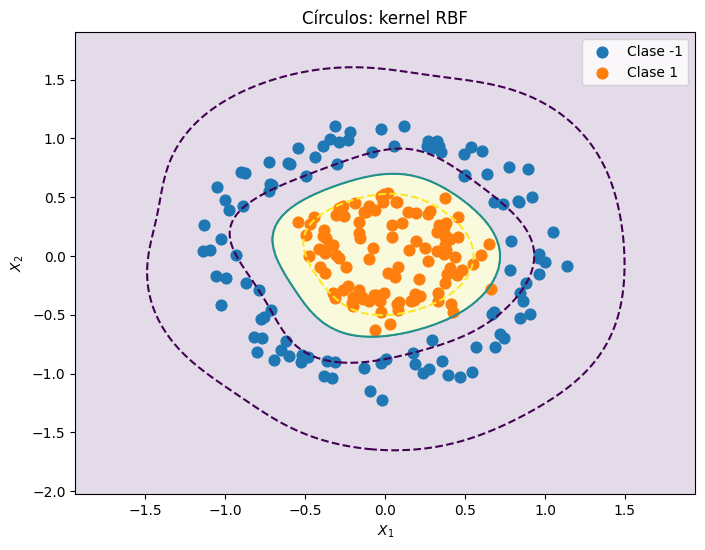

In [46]:
graficar_modelo(
    modelo_circulos_rbf,
    Xc_train,
    yc_train,
    titulo="Círculos: kernel RBF"
)

In [47]:
print(
    "Kernel lineal:",
    accuracy_score(
        yc_test,
        modelo_circulos_lineal.predict(Xc_test)
    )
)

print(
    "Kernel RBF:",
    accuracy_score(
        yc_test,
        modelo_circulos_rbf.predict(Xc_test)
    )
)

Kernel lineal: 0.5333333333333333
Kernel RBF: 1.0


## Ejercicios.

**14.22.1 Ejercicio 1. Kernel lineal y $C$.** Regresa al conjunto X generado con make_moons().

Ajusta dos modelos lineales:

$$
C = 0.001
$$

y

$$
C = 1000.
$$

Visualiza las fronteras.

In [1]:
valores_C = [
    0.001,
    100
]

for C in valores_C:
    
    modelo = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svc",
            SVC(
                kernel="linear",
                C=C
            )
        )
    ])
    
    modelo.fit(
        X_train,
        y_train
    )
    
    graficar_modelo(
        modelo,
        X_train,
        y_train,
        titulo=fr"RBF: $C={C}$, $\gamma=1$"
    )

NameError: name 'Pipeline' is not defined

¿Un valor extremadamente grande de $C$ permite que el kernel lineal reproduzca correctamente la estructura curva?

**R:** No.

**14.22.2 Ejercicio 2. Explorar $\gamma$.** Ajusta una SVM RBF con

$$
C = 10
$$

y compara:

$$
\gamma = 0.001, 1, 1000.
$$

Para cada modelo registra:

- accuracy de entrenamiento;
- accuracy de prueba;
- número de vectores de soporte.

Interpreta los resultados junto con las fronteras.

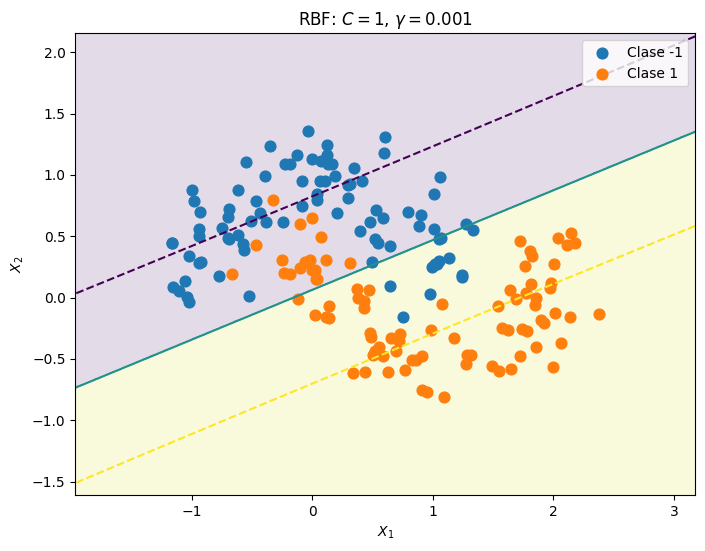

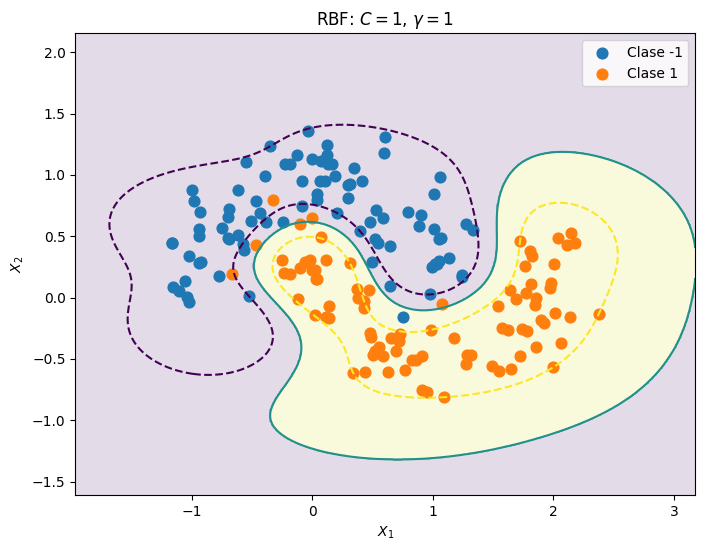

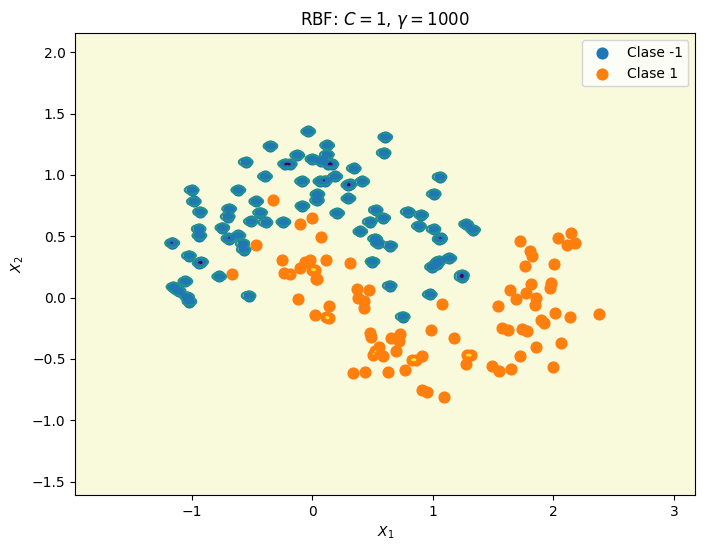

In [ ]:
valores_gamma = [
    0.001,
    1,
    1000
]

for gamma in valores_gamma:
    
    modelo = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svc",
            SVC(
                kernel="rbf",
                C=10,
                gamma=gamma
            )
        )
    ])
    
    modelo.fit(
        X_train,
        y_train
    )
    
    graficar_modelo(
        modelo,
        X_train,
        y_train,
        titulo=fr"RBF: $C=1$, $\gamma={gamma}$"
    )

In [ ]:
comparacion_gamma = []

for gamma in valores_gamma:
    
    modelo = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svc",
            SVC(
                kernel="rbf",
                C=1,
                gamma=gamma
            )
        )
    ])
    
    modelo.fit(
        X_train,
        y_train
    )
    
    comparacion_gamma.append({
        "gamma": gamma,
        "Accuracy_train": accuracy_score(
            y_train,
            modelo.predict(X_train)
        ),
        "Accuracy_test": accuracy_score(
            y_test,
            modelo.predict(X_test)
        )
    })

comparacion_gamma = pd.DataFrame(
    comparacion_gamma
)

comparacion_gamma

,gamma,Accuracy_train,Accuracy_test
0,0.001,0.702857,0.706667
1,1.000,0.954286,0.946667
2,1000.000,1.000000,0.546667


**R:** Notamos que un gamma muy alto no siempre es lo mejor y, además, puede engañarnos durante el entrenamiento.

**14.22.3 Ejercicio 3. Kernel polinomial.** Utiliza make_circles().

Ajusta modelos polinomiales con

$$
d = 2, 3, 4.
$$

Mantén constantes los demás hiperparámetros.

Compara las fronteras y el desempeño.


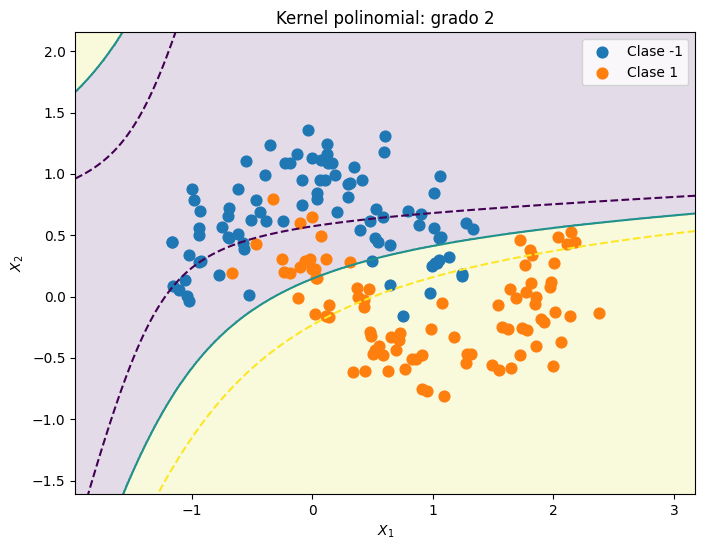

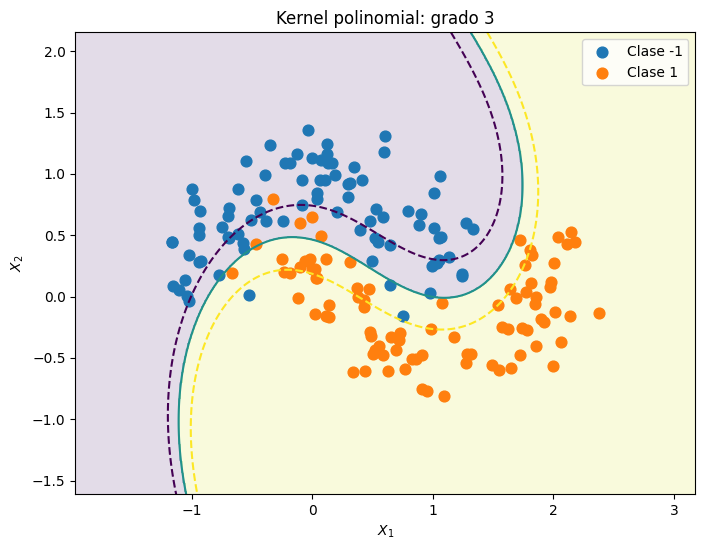

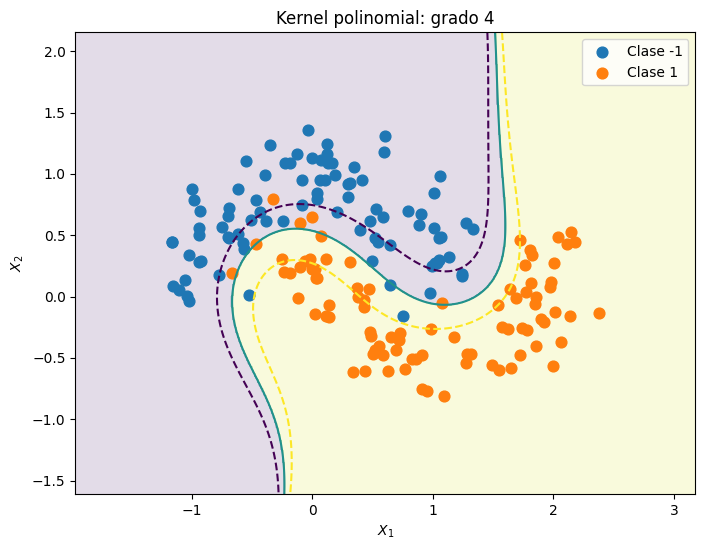

In [ ]:
grados = [2, 3, 4]

for grado in grados:
    
    modelo = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svc",
            SVC(
                kernel="poly",
                degree=grado,
                C=1,
                gamma="scale",
                coef0=1
            )
        )
    ])
    
    modelo.fit(
        X_train,
        y_train
    )
    
    graficar_modelo(
        modelo,
        X_train,
        y_train,
        titulo=f"Kernel polinomial: grado {grado}"
    )

In [ ]:
comparacion_grado = []

for grado in grados:
    
    modelo = Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "svc",
                SVC(
                    kernel="poly",
                    degree=grado,
                    C=1,
                    gamma="scale",
                    coef0=1
                )
            )
    ])
    
    modelo.fit(
        X_train,
        y_train
    )
    
    comparacion_grado.append({
        "grado": grado,
        "Accuracy_train": accuracy_score(
            y_train,
            modelo.predict(X_train)
        ),
        "Accuracy_test": accuracy_score(
            y_test,
            modelo.predict(X_test)
        )
    })

comparacion_grado = pd.DataFrame(
    comparacion_grado
)

comparacion_grado

,grado,Accuracy_train,Accuracy_test
0,2,0.845714,0.880000
1,3,0.954286,0.933333
2,4,0.948571,0.933333


**R:** Notamos que a partir de un grado tres no hay mucho aumento en el Accuracy.

**14.22.4 Ejercicio 4. Interpretación.** Sin ejecutar código, indica cuál de las siguientes modificaciones esperarías que produzca una influencia más local de cada observación en una SVM RBF:

$$
\gamma = 0.01
$$

o

$$
\gamma = 100
$$

Justifica utilizando

$$
K(x,z) = exp(-\gamma ∥x-z∥^{2}).
$$

**R:** La modificación que produce más influencia más local sería $\gamma = 100$ porque para los puntos que estén más alejados, $K(x,z)$ decae de manera más rápida.